# 影片處理示範（OpenCV + matplotlib）

同一份程式碼，用 **TensorFlow / PyTorch 課程第 8 講**的影像處理流程：上傳影片 → 按秒擷取畫面 → 擷取指定幀 → 灰階／邊緣／模糊 → 並排顯示。

## 用法

1. 按 **執行全部（Ctrl+F9）**，或逐格執行
2. 第 1 格會跳出檔案選擇框 —— **上傳你的 `.mp4`**
3. 不想上傳？直接按「取消」，會沿用 `DEFAULT_VIDEO`（先確認該檔已在左側 📁 檔案欄）

## 只改一個地方

檔名只在**第 1 格的 `DEFAULT_VIDEO`** 設定。上傳新檔時會自動抓取檔名，
**下面所有格子共用 `video_filename`，不用再 copy & paste**。

```python
DEFAULT_VIDEO = "testing-agent.mp4"   # ← 只改這裡
```

## 相關 notebook

| 檔案 | 內容 |
|---|---|
| `yolo_webcam_colab.ipynb` | 瀏覽器 webcam + YOLO 偵測 |
| `yolo_only.ipynb` | YOLO 最小版（圖片／合成影片） |
| `ivdc_exam_all_in_one.ipynb` | 完整考試自包含版 |


In [1]:
# ==========================================
# Cell [1]：上傳影片（唯一需要改檔名的地方）
# ==========================================
# 之後所有格子都會用呢個 video_filename，唔使再 copy & paste。
import os

from google.colab import files

# 預設檔名：冇上傳新檔時就用呢個（已存在於左側檔案欄就不用再 Run）
DEFAULT_VIDEO = "testing-agent.mp4"

print("請選擇影片檔（可直接按取消，沿用左側已有的檔）")
uploaded = files.upload()

if uploaded:
    # 只取第一個上傳的檔案（多選時也只認第一個）
    video_filename = list(uploaded.keys())[0]
    print(f"✅ 使用剛上傳的檔案：{video_filename}")
else:
    video_filename = DEFAULT_VIDEO
    print(f"ℹ️ 沒有上傳新檔，使用預設：{video_filename}")

# 立刻驗證檔案真的存在，避免後面幾格才爆錯
if not os.path.exists(video_filename):
    raise FileNotFoundError(
        f"找不到 {video_filename}\n"
        "  - 請在上一行重新上傳，或\n"
        f"  - 把 DEFAULT_VIDEO 改成左側檔案欄已有的檔名"
    )

_size = os.path.getsize(video_filename)
print(f"檔案大小：{_size:,} bytes")
print("下面所有格子都會自動使用 video_filename，無需再改。")


Saving testing-agent.mp4 to testing-agent.mp4
目前使用嘅影片檔案：testing-agent.mp4


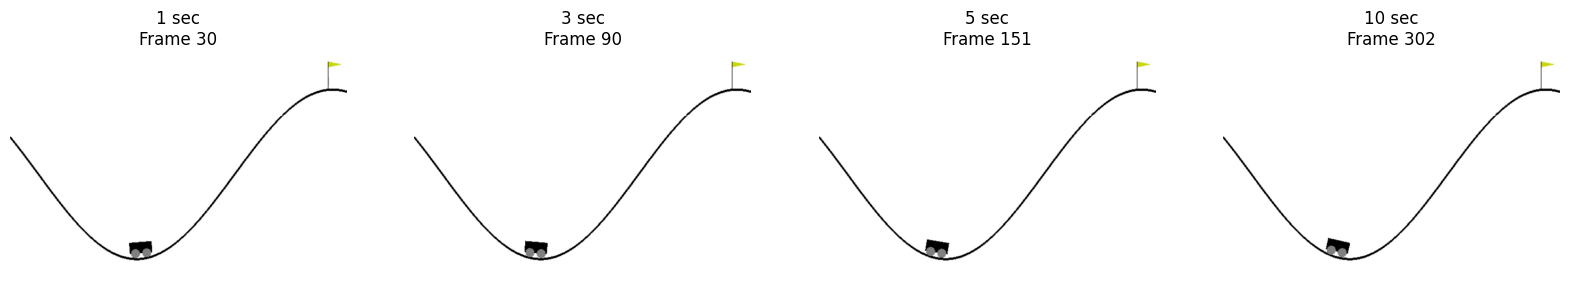

In [2]:
# ==========================================
# Cell [2]：按秒數擷取畫面並顯示
# ==========================================
import cv2
import matplotlib.pyplot as plt

# 統一從 Cell [1] 取得檔名（唔使再打）
cap = cv2.VideoCapture(video_filename)
if not cap.isOpened():
    raise RuntimeError(f"OpenCV 打不開 {video_filename}（格式不支援？試 .mp4 / .avi）")

# Get frames per second (FPS)
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"影片：{video_filename}  共 {total_frames} 幀 @ {fps:.1f} FPS")

# Choose seconds where you want frames
seconds = [1, 3, 5, 10]   # e.g., 1s, 3s, 5s, 10s
frames = []

for sec in seconds:
    frame_number = int(sec * fps)   # convert seconds to frame index
    if frame_number >= total_frames:
        print(f"  {sec}s -> frame {frame_number} 超出影片長度，跳過")
        continue
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ret, frame = cap.read()
    if ret and frame is not None:
        frames.append((sec, frame_number, frame))

cap.release()

# 安全檢查：影片太短時 frames 可能為空
if len(frames) > 0:
    fig, axes = plt.subplots(1, len(frames), figsize=(20, 5))
    if len(frames) == 1:
        axes = [axes]  # 確保 axes 永遠可以用 index 存取
    for i, (sec, frame_number, frame) in enumerate(frames):
        axes[i].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"{sec} sec\nFrame {frame_number}")
        axes[i].axis("off")
    plt.show()
else:
    print("無法讀取任何畫面，請確認影片檔案是否存在及長度是否足夠。")


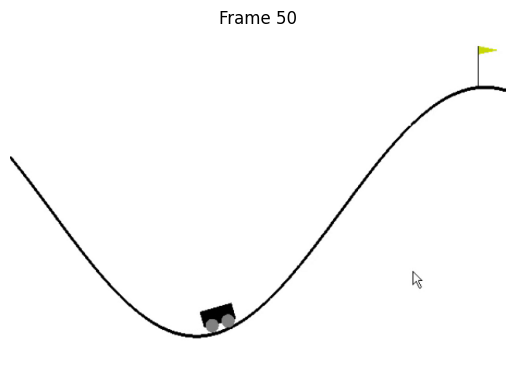

In [3]:
# ==========================================
# Cell [3]：擷取指定 Frame
# ==========================================
import cv2
import matplotlib.pyplot as plt

# 統一從 Cell [1] 取得檔名（唔使再打）
cap = cv2.VideoCapture(video_filename)

# Choose which frame number to show
frame_number = 50   # for example, the 50th frame

# 檢查總 Frame 數，防止指定嘅 frame_number 超出影片長度
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
if total_frames <= 0:
    cap.release()
    raise RuntimeError(f"讀不到 {video_filename} 的幀數，檔案可能已損壞或格式不支援")

if frame_number >= total_frames:
    print(f"提示：影片只有 {total_frames} frames，已自動改為讀取最後一個 frame ({total_frames - 1})")
    frame_number = total_frames - 1

# Jump directly to that frame
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
ret, frame = cap.read()
cap.release()

# 確保真係成功讀到張圖先做 BGR 轉 RGB，防止 empty assertion error
if ret and frame is not None:
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title(f"Frame {frame_number}  ({video_filename})")
    plt.axis("off")
    plt.show()
else:
    raise ValueError(
        f"讀取 Frame {frame_number} 失敗！請檢查 {video_filename} 是否已成功上傳到左側檔案欄。"
    )


In [ ]:
# ==========================================
# Cell [4]：影像處理（原圖、灰階、邊緣偵測、模糊）
# ==========================================
# 【改動 7】原本呢度唔使改邏輯，但因為 Cell [3] 修好咗，呢度嘅 `frame` 終於有實際影像資料！
# 【點解咁改】之前因為 Cell [3] 嘅 `frame` 係 `None`，所以呢格行 `cv2.cvtColor(frame, ...)` 會跟住爆同一個 OpenCV error。

# Original frame (color)
org = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Grayscale
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# Edge detection
edges = cv2.Canny(gray, 100, 200)

# Blur
blur = cv2.GaussianBlur(gray, (5, 5), 0)

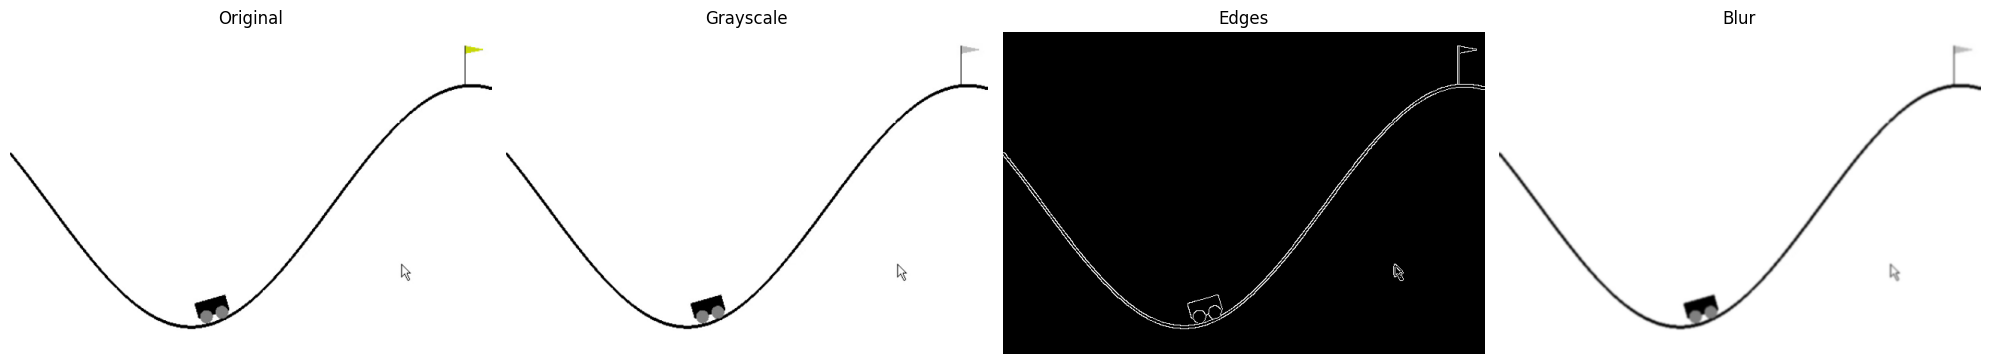

In [ ]:
# ==========================================
# Cell [5]：並排顯示 4 張處理後嘅圖片
# ==========================================
# 【改動 8】原本呢格報 `NameError: name 'org' is not defined`，原因係 Cell [4] 喺定義 `org` 嗰行出錯中斷咗。
#           而家 Cell [3] 同 Cell [4] 順利執行完，`org`、`gray`、`edges`、`blur` 全部已經成功定義，呢格可以原封不動正常執行！

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(org)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")
axes[1].axis("off")

axes[2].imshow(edges, cmap="gray")
axes[2].set_title("Edges")
axes[2].axis("off")

axes[3].imshow(blur, cmap="gray")
axes[3].set_title("Blur")
axes[3].axis("off")

plt.tight_layout()  # 【小優化】自動調整子圖間距，畫面更整齊
plt.show()